# Overview

This notebook visualizes the results of the hyperparameter sensitivity sweeps produced by `VC_execution.ipynb` (the `n_windows` / `min_cluster_size` / `pen` loops), to pick the best-performing parameter combination for each dataset.

**Paths:** defines the folders where each sweep's per-combination results were saved (`results_sensitivity` for CDLG, `results_Ostovar`/`results_Ceravolo`/`results_Bose` for CDRIFT).

**Sensitivity analysis CDLG:**
- Walks `results_sensitivity`, reading each combination's `evaluation_results_aggregated_level_cp_lag.csv` and pulling out the F1 score at lag 0.05.
- Parses the `windows`/`clusters`/`pen` values back out of each result folder's name.
- For each `pen` value, plots a heatmap of F1 score (color) across `windows` (x-axis) vs. `clusters` (y-axis), side by side, to visually compare how the three hyperparameters affect performance.

**Sensitivity analysis CDRIFT:**
- Same idea, but for the Ostovar, Ceravolo, and Bose result folders: reads each combination's `evaluation_report_general_0.05_lag.txt`, extracts the "average f1 score" via regex, parses `windows`/`clusters`/`pen` from the folder name, and renders the same per-`pen` heatmaps for each of the three datasets.

**Best Parameter combination:** records the hyperparameter combination (window size, cluster count, pen) that gave the best F1 score for each dataset (CDLG, CDRIFT-Ostovar, CDRIFT-Ceravolo, CDRIFT-Bose), read off from the heatmaps above.

# Paths

In [1]:
sensitivity_cdlg = "results_sensitivity"
sensitivity_Ostovar = "results_Ostovar"
sensitivity_Ceravolo = "results_Ceravolo"
sensitivity_Bose = "results_Bose"

# Sensitivity analysis CDLG

In [2]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt

def load_all_results(base_dir, filename="evaluation_results_aggregated_level_cp_lag.csv"):
    results = []
    
    for root, _, files in os.walk(base_dir):
        if filename in files:
            csv_path = os.path.join(root, filename)
            try:
                df = pd.read_csv(csv_path)
                results.append((root, df["0.05.2"][1]))
            except Exception as e:
                print(f"⚠️ Could not read {csv_path}: {e}")

    # Sort descending by F1_score
    #results.sort(key=lambda x: x[1]["0.05.2"][1], reverse=True)
    return results

results = load_all_results(sensitivity_cdlg)

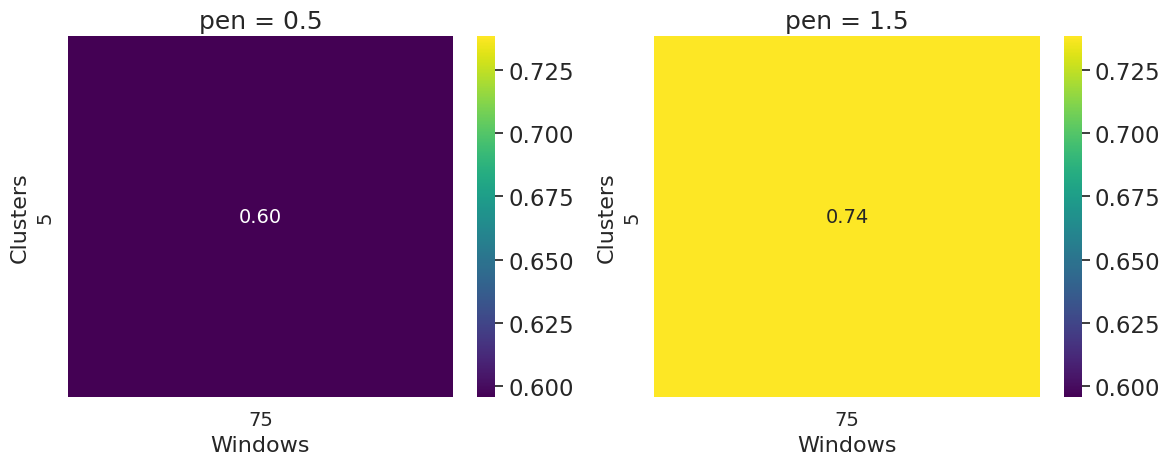

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

parsed = []
for path, score in results:
    score = float(score)

    windows  = int(re.search(r"windows_(\d+)", path).group(1))
    clusters = int(re.search(r"clusters_(\d+)", path).group(1))
    
    # Allow float pen values
    pen_str  = re.search(r"pen_([0-9.]+)", path).group(1)
    pen      = float(pen_str)

    parsed.append((windows, clusters, pen, score))

df = pd.DataFrame(parsed, columns=["windows", "clusters", "pen", "score"])

# Make all text larger globally
sns.set(font_scale=1.5)   # Increase this value if you want even bigger text

pen_values = sorted(df["pen"].unique())

vmin = df["score"].min()
vmax = df["score"].max()

fig, axes = plt.subplots(
    nrows=1,
    ncols=len(pen_values),
    figsize=(6 * len(pen_values), 5),
    squeeze=False
)

for ax, pen_value in zip(axes[0], pen_values):

    df_pen = df[df["pen"] == pen_value]

    heatmap_data = df_pen.pivot_table(
        index="clusters",
        columns="windows",
        values="score",
        aggfunc="mean"
    )

    sns.heatmap(
        heatmap_data,
        ax=ax,
        annot=True,
        fmt=".2f",
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
        annot_kws={"size": 14}  # annotation text size
    )

    ax.set_title(f"pen = {pen_value}", fontsize=18)
    ax.set_xlabel("Windows", fontsize=16)
    ax.set_ylabel("Clusters", fontsize=16)

    ax.tick_params(axis="both", labelsize=14)

plt.tight_layout()
plt.show()


# Sensitivity analysis CDRIFT

In [4]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt

def extract_f1_score(filepath):
    with open(filepath, "r", encoding="utf-8") as f:
        text = f.read()

    # regex to find the number after "average f1 score ... is:"
    match = re.search(r"average f1 score.*?is:\s*([0-9.]+)", text, re.IGNORECASE)
    if match:
        number_str = match.group(1).rstrip(".")   # <-- remove trailing dot
        return float(number_str)
    else:
        raise ValueError("F1 score not found in file")

def load_all_results(base_dir, filename="evaluation_report_general_0.05_lag.txt"):
    results = []
    
    for root, _, files in os.walk(base_dir):
        if filename in files:
            csv_path = os.path.join(root, filename)
            try:
                f1 = extract_f1_score(csv_path)
                results.append((root, f1))
            except Exception as e:
                print(f"⚠️ Could not read {csv_path}: {e}")

    return results

results_Ostovar = load_all_results(sensitivity_Ostovar)
results_Ceravolo = load_all_results(sensitivity_Ceravolo)
results_Bose = load_all_results(sensitivity_Bose)

def parse_sensitivity_results(results):
    parsed = []
    for path, score in results:
        score = float(score)

        windows  = int(re.search(r"windows_(\d+)", path).group(1))
        clusters = int(re.search(r"clusters_(\d+)", path).group(1))

        # Allow float pen values
        pen_str  = re.search(r"pen_([0-9.]+)", path).group(1)
        pen      = float(pen_str)

        parsed.append((windows, clusters, pen, score))

    return pd.DataFrame(parsed, columns=["windows", "clusters", "pen", "score"])

def plot_pen_heatmaps(df):
    import seaborn as sns

    pen_values = sorted(df["pen"].unique())

    # Shared color scale
    vmin = df["score"].min()
    vmax = df["score"].max()

    # Create one row of subplots
    fig, axes = plt.subplots(
        nrows=1,
        ncols=len(pen_values),
        figsize=(6 * len(pen_values), 5),
        squeeze=False
    )

    for ax, pen_value in zip(axes[0], pen_values):

        df_pen = df[df["pen"] == pen_value]

        heatmap_data = df_pen.pivot_table(
            index="clusters",
            columns="windows",
            values="score",
            aggfunc="mean"
        )

        sns.heatmap(
            heatmap_data,
            ax=ax,
            annot=True,
            fmt=".2f",
            cmap="viridis",
            vmin=vmin,
            vmax=vmax
        )

        ax.set_title(f"pen = {pen_value}")
        ax.set_xlabel("Windows")
        ax.set_ylabel("Clusters")

    plt.tight_layout()
    plt.show()

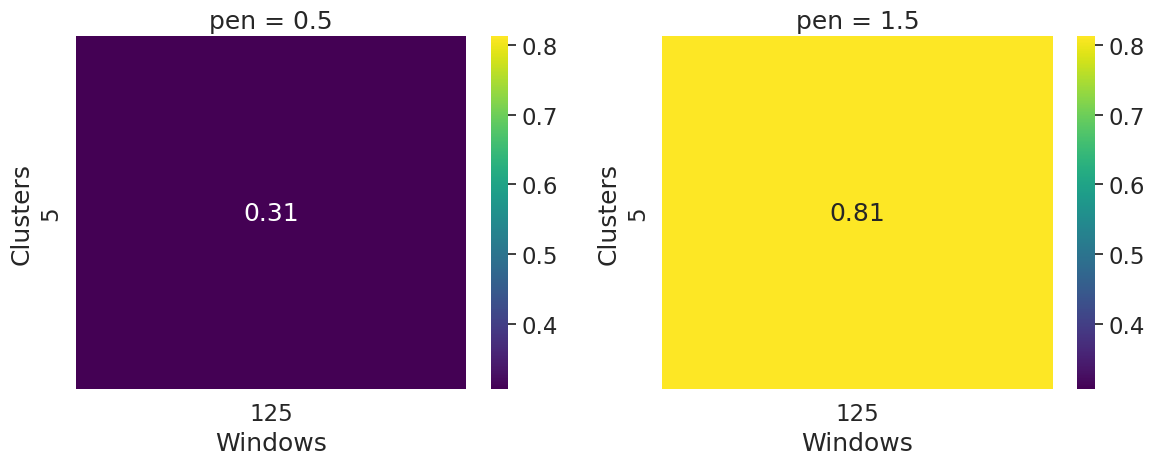

In [5]:
df = parse_sensitivity_results(results_Ostovar)
plot_pen_heatmaps(df)

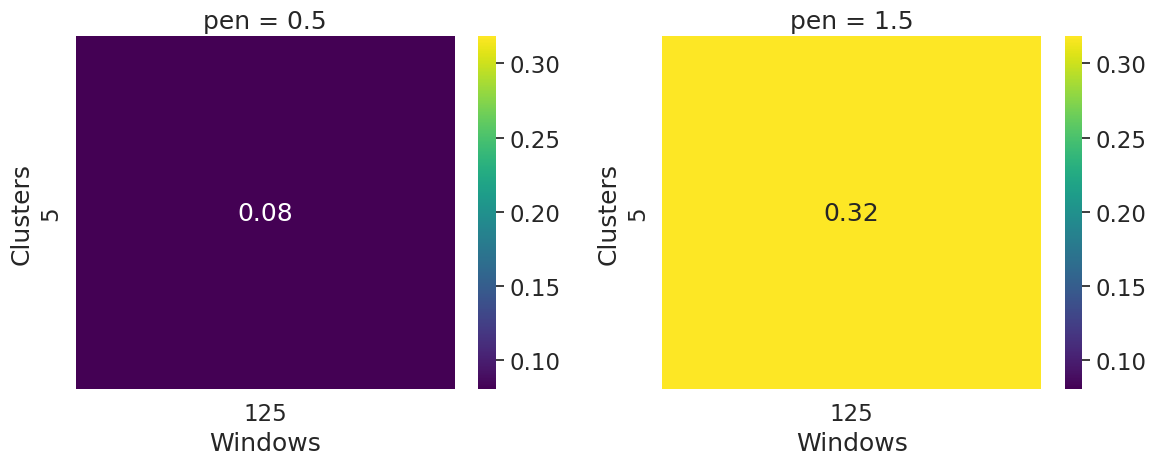

In [6]:
df = parse_sensitivity_results(results_Ceravolo)
plot_pen_heatmaps(df)

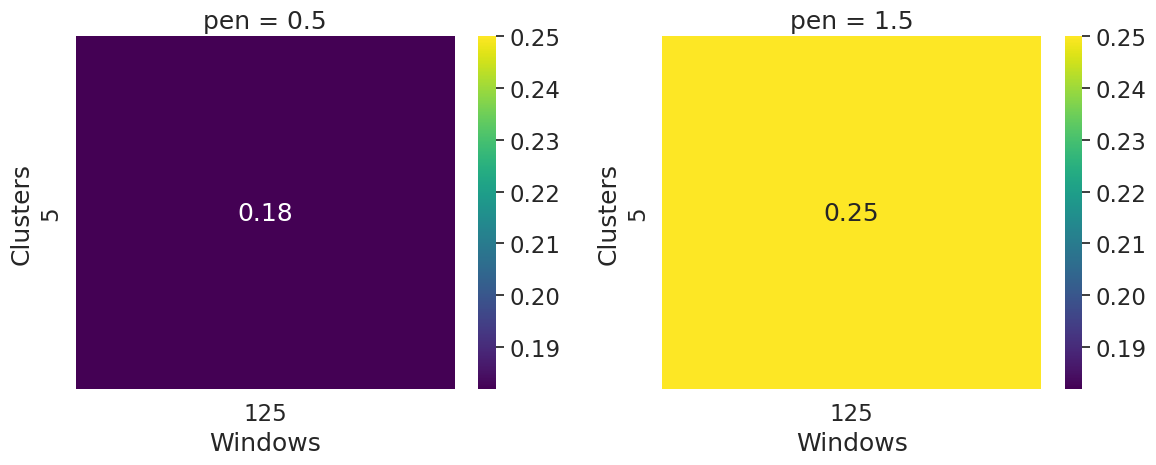

In [7]:
df = parse_sensitivity_results(results_Bose)
plot_pen_heatmaps(df)

# Best Parameter combination

1. CDLG: window:125 , clusters:10 , pen:1.5 
1. CDRIFT-Ostovar: window:75 , clusters:7 , pen:3 
1. CDRIFT-Cerabolo: window:125 , clusters:5 , pen:3 
1. CDRIFT-Bose: window:75 , clusters:5 , pen:3 